In [2]:
!pip install matplotlib datasets torch transformers evaluate

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 469.0/469.0 KB 21.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 103.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.4/81.4 KB 12.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.3/190.3 KB 26.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 213.0/213.0 KB 849.8 kB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.0/132.0 KB 19.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.5/110.5 KB 17.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 105.0 MB/s eta 0:00:00


In [3]:
import os
import random
import pandas as pd
from datasets import Dataset, Features, Value, ClassLabel
import collections
from collections import Counter
import matplotlib.pyplot as plt
from pathlib import Path
from datasets import DatasetDict
import evaluate
import torch
import numpy as np
from transformers import AdamW, AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, DataCollatorWithPadding
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
#training set
training_set = [os.path.join("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set", f) for f in os.listdir("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set")]

#test_set 
test_set = [os.path.join("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set", f) for f in os.listdir("/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set")]

#clarence dataset

#training set
#training_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/training-set/abstracts")]

#test_set 
#test_set = [os.path.join("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts", f) for f in os.listdir("/home/javi/git/bsc/debbie/Classifier/classifier-development/clarence-dataset/testing-set/abstracts")]

training_set = random.sample(training_set, len(training_set))
test_set = random.sample(test_set, len(test_set))

print("Total: " + str(len(training_set) + len(test_set)))
print("Training Set: " + str(len(training_set)))
print("Test Set: " + str(len(test_set)))

Total: 4165
Training Set: 2915
Test Set: 1250


In [6]:
#making labels, read the category from the name of the file 
def make_labels(data):
    files = data
    file_list = []
    train_labels = [None] * (len(files))
    count = 0
    docID = 0
    for fil in files:
        file_list.append(fil)
        train_labels[docID] = 'non-relevant'
        filepathTokens = fil.split('/')
        lastToken = filepathTokens[len(filepathTokens) - 1]
        if fil.endswith("_clinical.txt"):
            train_labels[docID] = 'clinical'
            count = count + 1
        elif fil.endswith("_non-clinical.txt"):
            train_labels[docID] = 'non-clinical'
            count = count + 1
        docID = docID + 1
    combined_labels_files = dict(zip(train_labels, file_list))
    #print (train_labels)
    #print (file_list)
    print (combined_labels_files)
    return train_labels, file_list, combined_labels_files
    

#make labels for multiclass training and test set
training_set_labels, file_list, combined_training = make_labels(training_set)
test_set_labels, test_file_list, combined_testing  = make_labels(test_set)

#dataframe with label and files, not text yet.
df_train = pd.DataFrame(data={ 'label':training_set_labels,'files': training_set})
df_test = pd.DataFrame(data={ 'label':test_set_labels,'files': test_set})
df_train

{'non-relevant': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set/23936518_background.txt', 'non-clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set/12382960_non-clinical.txt', 'clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/trainning_set/24288004_clinical.txt'}
{'non-relevant': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/25286823_background.txt', 'non-clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/23848958_non-clinical.txt', 'clinical': '/content/drive/MyDrive/Colab Notebooks/classifier-dataset/dataset/test_set/24396495_clinical.txt'}


,label,files
0,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
1,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
2,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
3,non-clinical,/content/drive/MyDrive/Colab Notebooks/classif...
4,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
...,...,...
2910,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
2911,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
2912,non-relevant,/content/drive/MyDrive/Colab Notebooks/classif...
2913,clinical,/content/drive/MyDrive/Colab Notebooks/classif...


Counter({'non-relevant': 1232, 'non-clinical': 844, 'clinical': 839})
OrderedDict([('clinical', 839), ('non-clinical', 844), ('non-relevant', 1232)])
[839, 844, 1232]


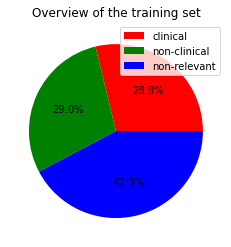

In [7]:
# to represent the distribution of the training set in a circular diagram

labels = ['clinical','non-clinical','non-relevant']

sizes = Counter(training_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the training set')
plt.show()

Counter({'non-relevant': 641, 'non-clinical': 361, 'clinical': 248})
OrderedDict([('clinical', 248), ('non-clinical', 361), ('non-relevant', 641)])
[248, 361, 641]


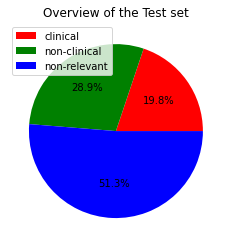

In [8]:
# to represent the distribution of the test:


labels = ['clinical','non-clinical','non-relevant']

sizes = Counter(test_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the Test set')
plt.show()

In [9]:
#load text of files 
X_train_text = [Path(file).read_text() for file in training_set]
X_test_text = [Path(file).read_text() for file in test_set]

In [10]:
df_train['text'] = X_train_text
df_test['text'] = X_test_text
df_train=df_train[["label", "text"]]
df_test=df_test[["label", "text"]]
df_train

,label,text
0,non-relevant,Monilethrix in pedigree.\nA 30-year-old female...
1,non-relevant,Definition of vascular territories on myocardi...
2,non-relevant,Perioperative outcomes in hybrid versus conven...
3,non-clinical,Meniscus ECM-functionalised hydrogels containi...
4,non-relevant,An Investigation and Suggestions for the Impro...
...,...,...
2910,non-relevant,Gut lymph and lymphatics: a source of factors ...
2911,non-relevant,Patella baja and total knee arthroplasty (TKA)...
2912,non-relevant,Flying between sky islands: the effect of natu...
2913,clinical,"Incidence, outcomes, and mortality of reintuba..."


In [11]:
#dataset_train = Dataset.from_pandas(df_train)
#dataset_test = Dataset.from_pandas(df_test)

debbie_class_names = ["clinical", "non-clinical","non-relevant"]
debbie_features = Features({'text': Value('string'), 'label': ClassLabel(names=debbie_class_names)})
dataset_train = Dataset.from_pandas(df_train, features=debbie_features)
dataset_test = Dataset.from_pandas(df_test, features=debbie_features)
dataset_train

Dataset({
    features: ['text', 'label'],
    num_rows: 2915
})

In [12]:
raw_dataset = DatasetDict({"train":dataset_train,"validation":dataset_test})
raw_dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1250
    })
})

In [13]:
raw_train_dataset = raw_dataset["train"]
raw_train_dataset[0]

{'text': 'Monilethrix in pedigree.\nA 30-year-old female patient presented with tiny papular scalp lesions with sparse, very short, curly hair of only 8 to 12 mm. Microscopic examination of hair revealed typical beaded or moniliform appearance. She also had typical lesions of psoriasis for past 2 months. Her father, 2 sisters and her 6-year-old daughter had similar types of beaded scalp hair.\n',
 'label': 2}

In [14]:
raw_train_dataset.features

{'text': Value(dtype='string', id=None),
 'label': ClassLabel(names=['clinical', 'non-clinical', 'non-relevant'], id=None)}

In [15]:

# Same as before
#checkpoint = "bert-base-uncased"
checkpoint = "dmis-lab/biobert-v1.1"

#model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

#esta parte de aqui no termina utilizandose solamnete el tokenizer


In [40]:
#revisar esta parte
from transformers import AutoConfig, AutoModelForSequenceClassification
# define the mappings as dictionaries
label2id = {'clinical':0, 'non-clinical':1, 'non-relevant': 2}
id2label = {0:'clinical', 1:'non-clinical', 2:'non-relevant'}
# define config
config = AutoConfig.from_pretrained(checkpoint, label2id=label2id, id2label=id2label, model_max_length=512)
# load model with config
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, config=config)
# export model
#model.save_pretrained(target_name_or_path)

loading configuration file config.json from cache at /root/.cache/huggingface/hub/models--dmis-lab--biobert-v1.1/snapshots/551ca18efd7f052c8dfa0b01c94c2a8e68bc5488/config.json
Model config BertConfig {
  "_name_or_path": "dmis-lab/biobert-v1.1",
  "architectures": [
    "BertModel"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "id2label": {
    "0": "clinical",
    "1": "non-clinical",
    "2": "non-relevant"
  },
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "label2id": {
    "clinical": 0,
    "non-clinical": 1,
    "non-relevant": 2
  },
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.26.1",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size"

In [41]:
def tokenize_function(example):
    return tokenizer(example["text"], truncation=True) #cuidado agregue padding para usar la segunda opcion

In [42]:
tokenized_datasets = raw_dataset.map(tokenize_function, batched=True)
tokenized_datasets

Map:   0%|          | 0/2915 [00:00<?, ? examples/s]

Map:   0%|          | 0/1250 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2915
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1250
    })
})

In [19]:
#tokenized_datasets['train'][0]

In [43]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

In [44]:
def compute_metrics(eval_pred):
    metric1 = evaluate.load("precision")
    metric2 = evaluate.load("recall")
    metric3 = evaluate.load("accuracy")
    metric4 = evaluate.load("f1")
    #metric5 = evaluate.load("BucketHeadP65/confusion_matrix")
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision = metric1.compute(predictions=predictions, references=labels, average = 'macro')["precision"]
    recall = metric2.compute(predictions=predictions, references=labels, average = 'macro')["recall"]
    accuracy = metric3.compute(predictions=predictions, references=labels)["accuracy"]
    f1 = metric4.compute(predictions=predictions, references=labels, average = 'macro')["f1"]
    #confusion_matrix = metric5.compute(predictions=predictions, references=labels)["confusion_matrix"]
    return {"precision": precision, "recall": recall, "accuracy": accuracy, "f1": f1}

# Epoch = 3

In [45]:
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch")
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).


In [46]:
trainer.train()

The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 3
  Instantaneous batch size per device = 8
  Total train batch size (w. parallel, distributed & accumulation) = 8
  Gradient Accumulation steps = 1
  Total optimization steps = 1095
  Number of trainable parameters = 108312579


Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.294614,0.867517,0.908004,0.882400,0.877294
2,0.323200,0.462959,0.860808,0.907584,0.880000,0.873333
3,0.186000,0.375789,0.884608,0.914272,0.904800,0.896071


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=1095, training_loss=0.24557404278620193, metrics={'train_runtime': 1019.2585, 'train_samples_per_second': 8.58, 'train_steps_per_second': 1.074, 'total_flos': 2292865906253076.0, 'train_loss': 0.24557404278620193, 'epoch': 3.0})

In [47]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]

predictions = np.argmax(logits, axis=-1)


The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


In [48]:
labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)

              precision    recall  f1-score   support

    clinical       0.74      0.90      0.81       248
non-clinical       0.96      0.98      0.97       361
non-relevant       0.96      0.86      0.91       641

    accuracy                           0.90      1250
   macro avg       0.88      0.91      0.90      1250
weighted avg       0.91      0.90      0.91      1250

Confusion Matrix: [[222   5  21]
 [  2 355   4]
 [ 77  10 554]]


<AxesSubplot:>

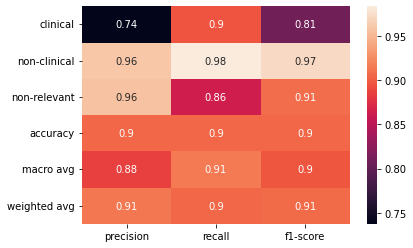

In [49]:
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

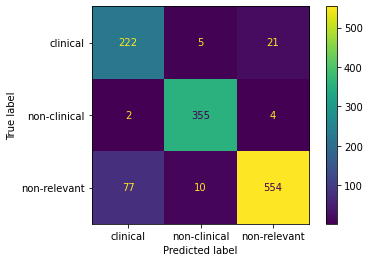

In [50]:

disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [52]:
#Save the model to path
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/special_tokens_map.json


# Epoch 5

In [29]:
#with 5
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=5)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 5
  Instantaneous batch size per device = 8
  Total train batch size (w. p

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.502407,0.884476,0.879071,0.896800,0.881670
2,0.169800,0.525280,0.874331,0.905238,0.896000,0.886466
3,0.078700,0.600688,0.875852,0.899638,0.896800,0.885336
4,0.078700,0.564000,0.885622,0.908603,0.905600,0.895459
5,0.045000,0.608121,0.884086,0.913670,0.903200,0.895213


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=1825, training_loss=0.08286933245724194, metrics={'train_runtime': 1730.7624, 'train_samples_per_second': 8.421, 'train_steps_per_second': 1.054, 'total_flos': 3820356463857948.0, 'train_loss': 0.08286933245724194, 'epoch': 5.0})

In [30]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]

predictions = np.argmax(logits, axis=-1)

labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.73      0.90      0.81       248
non-clinical       0.96      0.98      0.97       361
non-relevant       0.95      0.86      0.91       641

    accuracy                           0.90      1250
   macro avg       0.88      0.91      0.90      1250
weighted avg       0.91      0.90      0.91      1250

Confusion Matrix: [[224   4  20]
 [  2 352   7]
 [ 79   9 553]]


<AxesSubplot:>

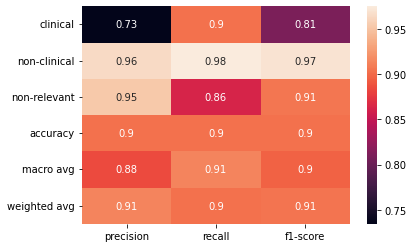

In [31]:
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

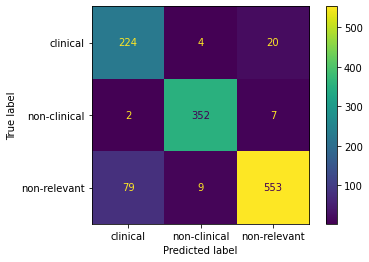

In [32]:
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

# Epoch = 2

In [33]:
#with 2
#using the Trainer Api 
training_args = TrainingArguments("debbie-trainer", evaluation_strategy="epoch", num_train_epochs=2)
trainer = Trainer(
    model,
    training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],#validation goes here 
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer.train()

PyTorch: setting up devices
The default value for the training argument `--report_to` will change in v5 (from all installed integrations to none). In v5, you will need to use `--report_to all` to get the same behavior as now. You should start updating your code and make this info disappear :-).
The following columns in the training set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
/usr/local/lib/python3.8/dist-packages/transformers/optimization.py:306: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(
***** Running training *****
  Num examples = 2915
  Num Epochs = 2
  Instantaneous batch size per device = 8
  Total train batch size (w. p

Epoch,Training Loss,Validation Loss,Precision,Recall,Accuracy,F1
1,No log,0.687858,0.872557,0.897073,0.892800,0.881820
2,0.063800,0.710633,0.884226,0.897475,0.902400,0.890378


The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  Batch size = 8
Saving model checkpoint to debbie-trainer/checkpoint-500
Configuration saved in debbie-trainer/checkpoint-500/config.json
Model weights saved in debbie-trainer/checkpoint-500/pytorch_model.bin
tokenizer config file saved in debbie-trainer/checkpoint-500/tokenizer_config.json
Special tokens file saved in debbie-trainer/checkpoint-500/special_tokens_map.json
The following columns in the evaluation set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Evaluation *****
  Num examples = 1250
  

TrainOutput(global_step=730, training_loss=0.04823505911108566, metrics={'train_runtime': 690.4801, 'train_samples_per_second': 8.443, 'train_steps_per_second': 1.057, 'total_flos': 1528311759248484.0, 'train_loss': 0.04823505911108566, 'epoch': 2.0})

In [34]:
eval_pred = trainer.predict(test_dataset=tokenized_datasets["validation"])
logits, labels = eval_pred[:2]

predictions = np.argmax(logits, axis=-1)

labels2 = ['clinical','non-clinical','non-relevant']
class_report = classification_report(y_true=labels, y_pred=predictions,target_names=labels2)
print(class_report)
conf_matrix = confusion_matrix(labels, predictions)
print('Confusion Matrix:',conf_matrix)

The following columns in the test set don't have a corresponding argument in `BertForSequenceClassification.forward` and have been ignored: text. If text are not expected by `BertForSequenceClassification.forward`,  you can safely ignore this message.
***** Running Prediction *****
  Num examples = 1250
  Batch size = 8


              precision    recall  f1-score   support

    clinical       0.77      0.82      0.80       248
non-clinical       0.95      0.98      0.97       361
non-relevant       0.93      0.89      0.91       641

    accuracy                           0.90      1250
   macro avg       0.88      0.90      0.89      1250
weighted avg       0.90      0.90      0.90      1250

Confusion Matrix: [[204   7  37]
 [  0 354   7]
 [ 60  11 570]]


<AxesSubplot:>

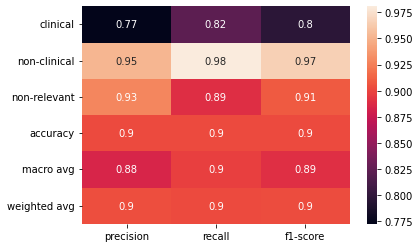

In [35]:
clf_report = classification_report(y_true=labels, y_pred=predictions,output_dict=True,target_names=labels2)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

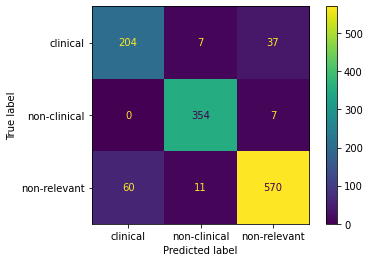

In [36]:
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix,display_labels=labels2)
disp.plot()

In [37]:
trainer.save_model("drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0")

Saving model checkpoint to drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0
Configuration saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/config.json
Model weights saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/pytorch_model.bin
tokenizer config file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/tokenizer_config.json
Special tokens file saved in drive/MyDrive/Colab Notebooks/debbie-classifier-model-transformers-1.0.0/special_tokens_map.json
